# IEEE118 EMT component timing comparison

Fresh detailed profiles use Δt = 50 µs and T_sim = 30 s. SSN, Aggregate, and Grouped passive huge SSN have five sequential wall-time runs; Conventional has one completed run as requested. Component-family and stage bars use the representative median-wall-time profile for each configuration, while wall-to-wall values use the measured mean (or the single conventional run). The older SSN-generator variant is omitted because it was not part of this verified rerun set.

In [1]:
from pathlib import Path
import csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path("examples/Notebooks/Benchmarks/data/verified_rerun")
if not DATA.exists():
    DATA = Path("data/verified_rerun")
CONFIGS = ["conventional", "ssn", "aggregate", "grouped_passive_huge_ssn"]
DISPLAY = {
    "conventional": "Conventional (n=1)",
    "ssn": "SSN (n=5)",
    "aggregate": "Aggregate (n=5)",
    "grouped_passive_huge_ssn": "Grouped passive huge SSN (n=5)",
}
DISPLAY_ORDER = [DISPLAY[c] for c in CONFIGS]
COLORS = ["#4472c4", "#ed7d31", "#59a14f", "#b279a2"]


def load_tasks(configuration):
    rows = []
    with (DATA / f"{configuration}_TaskTimes.csv").open() as f:
        for name, avg_ns, min_ns, max_ns, calls in csv.reader(f):
            stage = name.rsplit(".", 1)[-1] if "." in name else "other"
            component = name.rsplit(".", 1)[0] if "." in name else name
            if stage in {"MnaPreStep", "MnaPostStep", "Solve"}:
                rows.append(
                    {
                        "configuration": configuration,
                        "component": component,
                        "stage": stage,
                        "avg_us": int(avg_ns) / 1000,
                        "calls": int(calls),
                        "cumulative_s": int(avg_ns) * int(calls) / 1e9,
                    }
                )
    return pd.DataFrame(rows)


tasks = pd.concat([load_tasks(c) for c in CONFIGS], ignore_index=True)


def family(name):
    if name.startswith("Gen"):
        return "Generators"
    if name.startswith("Trafo"):
        return "Transformers"
    if name.startswith("LinearNetworkGroup"):
        return "Grouped passive huge SSN"
    if name.startswith("LinearNetwork"):
        return "Linear aggregate"
    if name.startswith("Line"):
        return "PiLines"
    if name.startswith(("ImpedanceLoad", "Load", "Shunt")):
        return "Loads + shunts"
    return "Other"


tasks["family"] = tasks["component"].map(family)
component_tasks = tasks[tasks.stage.isin(["MnaPreStep", "MnaPostStep"])]
family_totals = (
    component_tasks.groupby(["configuration", "family", "stage"])["cumulative_s"]
    .sum()
    .unstack("stage", fill_value=0)
    .reset_index()
)
for stage_name in ["MnaPreStep", "MnaPostStep"]:
    if stage_name not in family_totals:
        family_totals[stage_name] = 0.0
family_totals["total_s"] = family_totals["MnaPreStep"] + family_totals["MnaPostStep"]
families = [
    "PiLines",
    "Generators",
    "Transformers",
    "Loads + shunts",
    "Linear aggregate",
    "Grouped passive huge SSN",
]
family_totals = family_totals[family_totals.family.isin(families)]
family_totals

stage,configuration,family,MnaPostStep,MnaPreStep,total_s
0,aggregate,Generators,3.836394,8.620786,12.457179
1,aggregate,Linear aggregate,10.034983,8.618386,18.653369
2,conventional,Generators,3.792594,10.847382,14.639976
3,conventional,Loads + shunts,16.151373,7.748387,23.899760
4,conventional,PiLines,77.801870,28.006753,105.808624
5,conventional,Transformers,3.547194,2.447996,5.995190
6,grouped_passive_huge_ssn,Generators,3.799194,7.730987,11.530181
7,grouped_passive_huge_ssn,Grouped passive huge SSN,19.739967,0.010800,19.750767
8,ssn,Generators,3.847194,8.861385,12.708579
9,ssn,Loads + shunts,1.378198,1.071598,2.449796


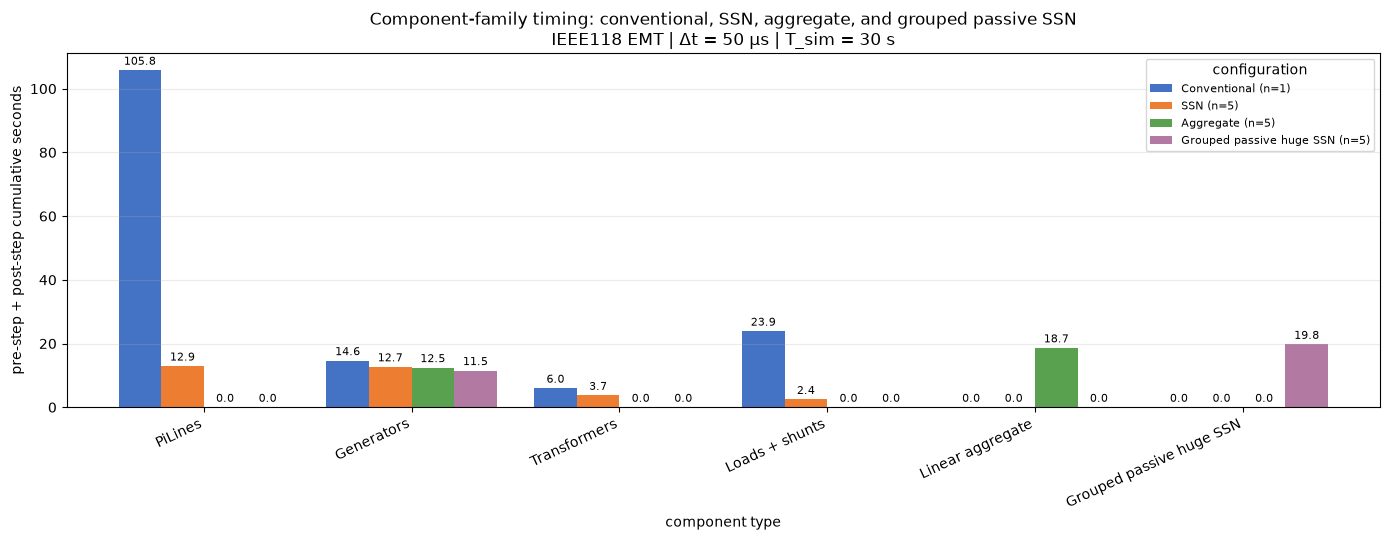

In [2]:
# Figure 1: cumulative pre/post component time by family, from the verified profiles.
wide = (
    family_totals.pivot(index="family", columns="configuration", values="total_s")
    .reindex(families)
    .fillna(0)
)
wide = wide.rename(columns=DISPLAY).reindex(columns=DISPLAY_ORDER)
ax = wide.plot.bar(figsize=(14, 5.5), color=COLORS, width=0.82)
ax.set_title(
    "Component-family timing: conventional, SSN, aggregate, and grouped passive SSN\nIEEE118 EMT | Δt = 50 µs | T_sim = 30 s"
)
ax.set_ylabel("pre-step + post-step cumulative seconds")
ax.set_xlabel("component type")
ax.grid(axis="y", alpha=0.25)
ax.legend(title="configuration", fontsize=8)
ax.set_xticklabels(ax.get_xticklabels(), rotation=25, ha="right")
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=2, fontsize=8)
plt.tight_layout()
plt.show()

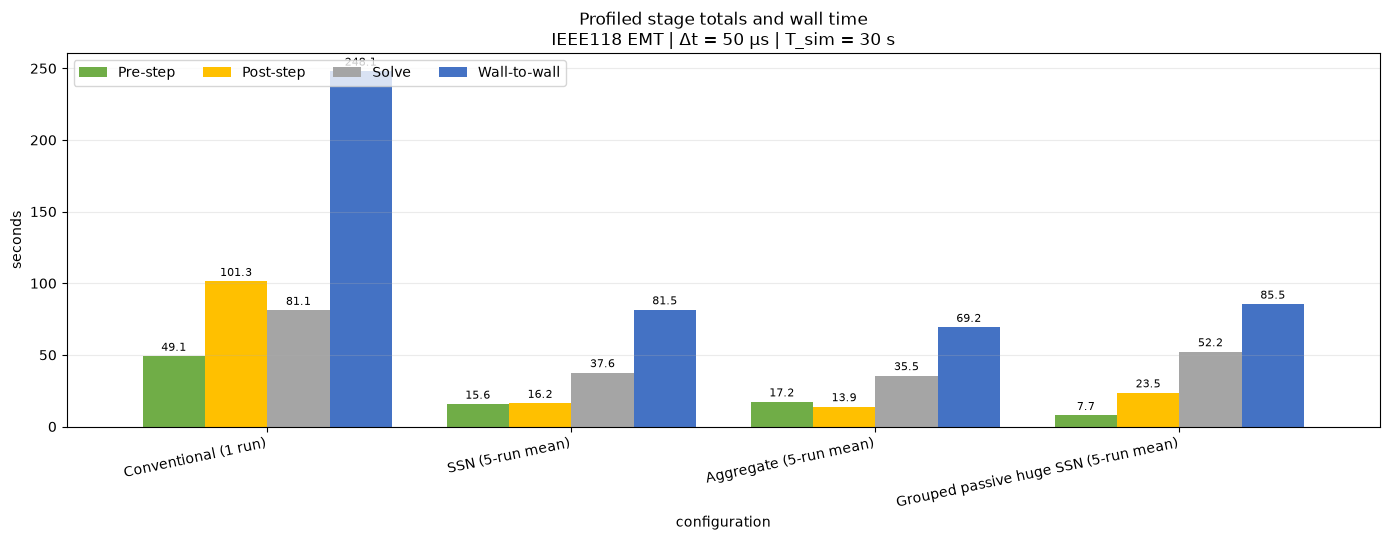

,Pre-step,Post-step,Solve,Wall-to-wall
Conventional (n=1),49.051,101.293,81.088,248.060
SSN (n=5),15.629,16.205,37.608,81.488
Aggregate (n=5),17.239,13.871,35.547,69.246
Grouped passive huge SSN (n=5),7.742,23.539,52.242,85.462


In [3]:
# Figure 2: profiled simulation stages and measured wall-to-wall time.
n_steps = 599999
stage = (
    tasks.groupby(["configuration", "stage"])["cumulative_s"]
    .sum()
    .unstack(fill_value=0)
)
wall_mean = {
    "conventional": 248.06,
    "ssn": 81.488,
    "aggregate": 69.246,
    "grouped_passive_huge_ssn": 85.462,
}
stage_plot = pd.DataFrame(
    {
        "Pre-step": stage["MnaPreStep"],
        "Post-step": stage["MnaPostStep"],
        "Solve": stage["Solve"],
        "Wall-to-wall": pd.Series(wall_mean),
    }
)
stage_plot = stage_plot.rename(index=DISPLAY).reindex(DISPLAY_ORDER)
ax = stage_plot.plot.bar(
    figsize=(14, 5.5), color=["#70ad47", "#ffc000", "#a5a5a5", "#4472c4"], width=0.82
)
ax.set_title(
    "Profiled stage totals and wall time\nIEEE118 EMT | Δt = 50 µs | T_sim = 30 s"
)
ax.set_ylabel("seconds")
ax.set_xlabel("configuration")
ax.grid(axis="y", alpha=0.25)
ax.legend(ncol=4, loc="upper left")
ax.set_xticklabels(
    [
        "Conventional (1 run)",
        "SSN (5-run mean)",
        "Aggregate (5-run mean)",
        "Grouped passive huge SSN (5-run mean)",
    ],
    rotation=12,
    ha="right",
)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=2, fontsize=8)
plt.tight_layout()
plt.show()
display(stage_plot.round(3))

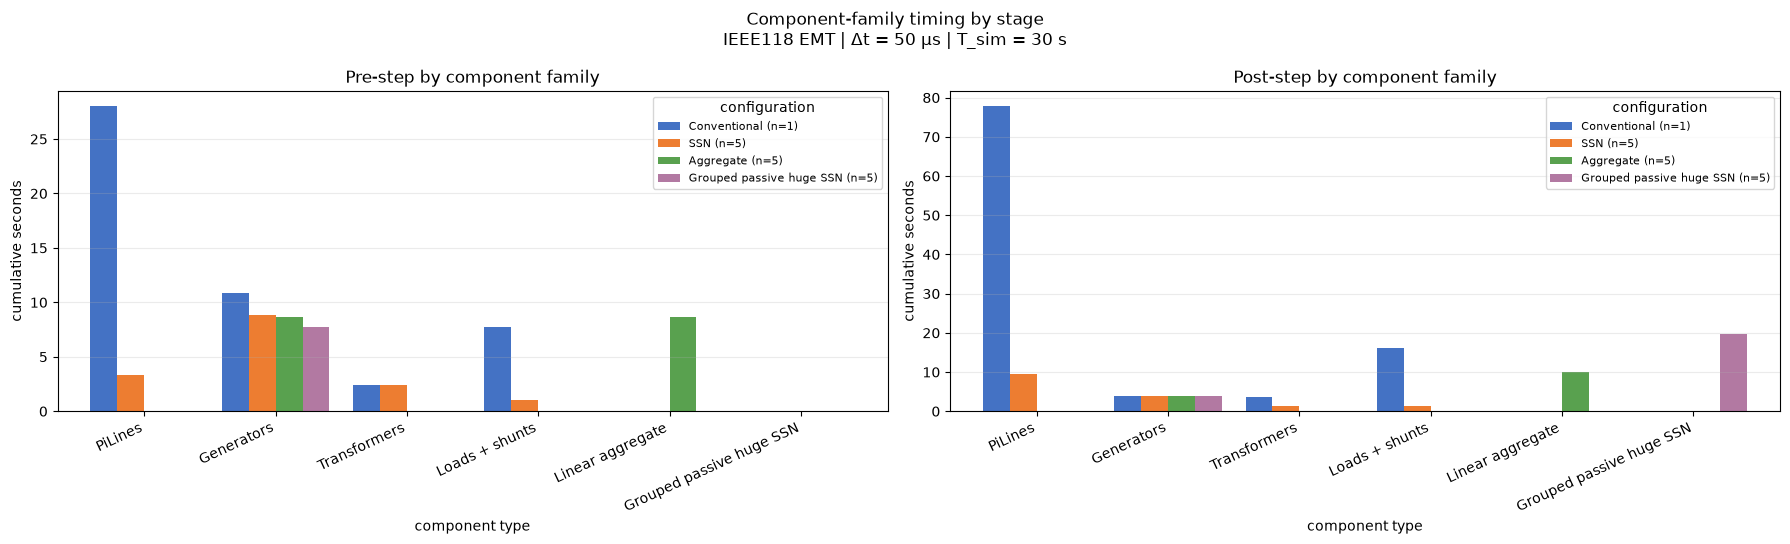

In [4]:
# Figure 3: compare pre-step with pre-step and post-step with post-step by family.
pre = (
    family_totals.pivot(index="family", columns="configuration", values="MnaPreStep")
    .reindex(families)
    .fillna(0)
)
post = (
    family_totals.pivot(index="family", columns="configuration", values="MnaPostStep")
    .reindex(families)
    .fillna(0)
)
pre = pre.rename(columns=DISPLAY).reindex(columns=DISPLAY_ORDER)
post = post.rename(columns=DISPLAY).reindex(columns=DISPLAY_ORDER)
fig, axes = plt.subplots(1, 2, figsize=(18, 5.5), sharey=False)
pre.plot.bar(ax=axes[0], color=COLORS, width=0.82)
post.plot.bar(ax=axes[1], color=COLORS, width=0.82)
for ax, title in zip(
    axes, ["Pre-step by component family", "Post-step by component family"]
):
    ax.set_title(title)
    ax.set_ylabel("cumulative seconds")
    ax.set_xlabel("component type")
    ax.grid(axis="y", alpha=0.25)
    ax.legend(title="configuration", fontsize=8)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=25, ha="right")
fig.suptitle(
    "Component-family timing by stage\nIEEE118 EMT | Δt = 50 µs | T_sim = 30 s"
)
fig.tight_layout()
plt.show()

In [5]:
def load_steps(configuration):
    values = []
    with (DATA / f"{configuration}_StepTimes.log").open() as f:
        for line in f:
            value = line.strip()
            if value and value != "step_time":
                values.append(float(value) * 1000.0)
    return np.asarray(values)


assert set(tasks.stage.unique()) == {"MnaPreStep", "MnaPostStep", "Solve"}
assert all(load_steps(c).size == n_steps for c in CONFIGS)
assert wall_mean == {
    "conventional": 248.06,
    "ssn": 81.488,
    "aggregate": 69.246,
    "grouped_passive_huge_ssn": 85.462,
}
print(f"All four configurations have {n_steps:,} measured steps.")
print(
    "Wall time: conventional n=1; SSN, aggregate, and grouped passive huge SSN n=5 each."
)

All four configurations have 599,999 measured steps.
Wall time: conventional n=1; SSN, aggregate, and grouped passive huge SSN n=5 each.


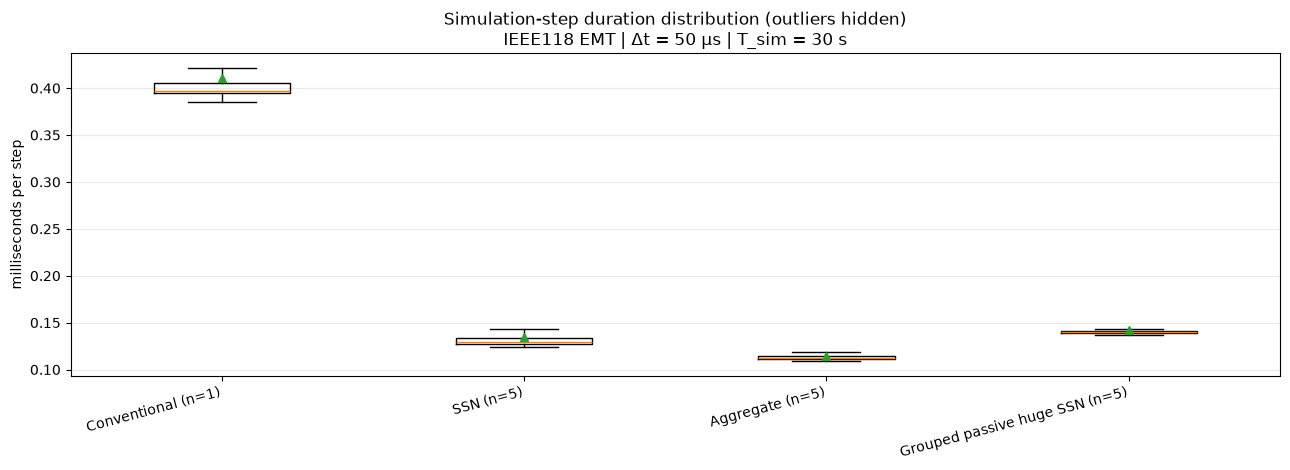

,configuration,mean_ms,median_ms,p95_ms,max_ms
0,Conventional (n=1),0.4112,0.3966,0.4580,72.8988
1,SSN (n=5),0.1352,0.1292,0.1468,62.8997
2,Aggregate (n=5),0.1145,0.1118,0.1228,35.1694
3,Grouped passive huge SSN (n=5),0.1420,0.1398,0.1501,42.2432


In [6]:
# Per-step duration distributions from the same representative verified profiles.
step_labels = DISPLAY_ORDER
step_arrays = [load_steps(c) for c in CONFIGS]
fig, ax = plt.subplots(figsize=(13, 4.8))
ax.boxplot(step_arrays, tick_labels=step_labels, showfliers=False, showmeans=True)
ax.set_title(
    "Simulation-step duration distribution (outliers hidden)\nIEEE118 EMT | Δt = 50 µs | T_sim = 30 s"
)
ax.set_ylabel("milliseconds per step")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()
pd.DataFrame(
    {
        "configuration": step_labels,
        "mean_ms": [x.mean() for x in step_arrays],
        "median_ms": [np.median(x) for x in step_arrays],
        "p95_ms": [np.percentile(x, 95) for x in step_arrays],
        "max_ms": [x.max() for x in step_arrays],
    }
).round(4)